In [1]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import os
import sys

REPO = "/workspace/NeuroVision"

sys.path.append(f"{REPO}/src")
os.chdir(f"{REPO}/notebooks")
for folder in ("models", "reports"):
    os.makedirs(f"{REPO}/{folder}", exist_ok=True)

2026-10-29 10:40:26.769374: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793270426.793904    4299 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793270426.801552    4299 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793270426.820832    4299 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793270426.820851    4299 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793270426.820853    4299 computation_placer.cc:177] computation placer alr

### Load and split the data

In [2]:
from neurovision.preprocessing import prepare_data, make_dataset

data = prepare_data("../data/raw", seed=42)
X_train, y_train, p_train = data["train"]
X_val, y_val, p_val = data["val"]
X_test, y_test, p_test = data["test"]

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

I0000 00:00:1793270453.590965    4299 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1198 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


### Build the CNN and inspect it

In [3]:
from neurovision.model import build_model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,860 (1007.27 KB)

 Trainable params: 257,860 (1007.27 KB)

 Non-trainable params: 0 (0.00 B)

### Class weights computed on the training set only

In [4]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from neurovision.preprocessing import encoder

y_train_idx = encoder.transform(y_train)
weights = compute_class_weight("balanced", classes=np.arange(4), y=y_train_idx)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(1.0379188712522045), 1: np.float64(1.0288461538461537), 2: np.float64(0.9711221122112211), 3: np.float64(0.9663382594417077)}


### Callbacks: save the best model, stop early, resume after interruption

In [5]:
from neurovision.tracking import MlflowEpochLogger, log_training_summary, setup_mlflow, start_run

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/best_model.keras", monitor="val_accuracy", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.BackupAndRestore(backup_dir="../models/backup"),
    MlflowEpochLogger(),
]

### Train the model and measure the training time

In [6]:
import time

import mlflow
from neurovision.tracking import log_training_summary, setup_mlflow, start_run

EPOCHS = 20

setup_mlflow()
start_run("cnn_scratch", tags={"stage": "training", "model_type": "cnn"})
mlflow.log_params({
    "epochs_max": EPOCHS,
    "early_stopping_patience": 5,
    "seed": 42,
    "n_train": len(X_train),
    "n_val": len(X_val),
    "n_test": len(X_test),
    "total_params": model.count_params(),
})

start = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)
duration = time.time() - start
print(f"Training time: {duration / 60:.1f} min for {len(history.history['loss'])} epoch(s)")
log_training_summary(history, duration, model_path="../models/best_model.keras")

2026/10/29 10:40:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/29 10:40:58 INFO mlflow.store.db.utils: Updating database tables


Epoch 1/20


I0000 00:00:1793270462.962577    4611 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/148 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.1753 - loss: 1.3952 

2026-10-29 10:41:05.311269: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:382] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.


148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.4384 - loss: 1.1732 - val_accuracy: 0.3399 - val_loss: 1.9596
Epoch 2/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.5746 - loss: 0.9953 - val_accuracy: 0.4054 - val_loss: 1.2989
Epoch 3/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.6130 - loss: 0.9019 - val_accuracy: 0.5312 - val_loss: 0.9985
Epoch 4/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.6627 - loss: 0.7983 - val_accuracy: 0.7037 - val_loss: 0.7328
Epoch 5/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.6952 - loss: 0.7246 - val_accuracy: 0.6819 - val_loss: 0.7927
Epoch 6/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.7143 - loss: 0.6871 - val_accuracy: 0.6561 - val_loss: 0.8305
Epoch 7/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.7311 - loss: 0.6698 - val_accuracy: 0.7225 - val_loss: 0.6375
Epoch 8/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.7351 - loss: 0.6374 - val_accuracy: 0.80

### Learning curves: accuracy and loss

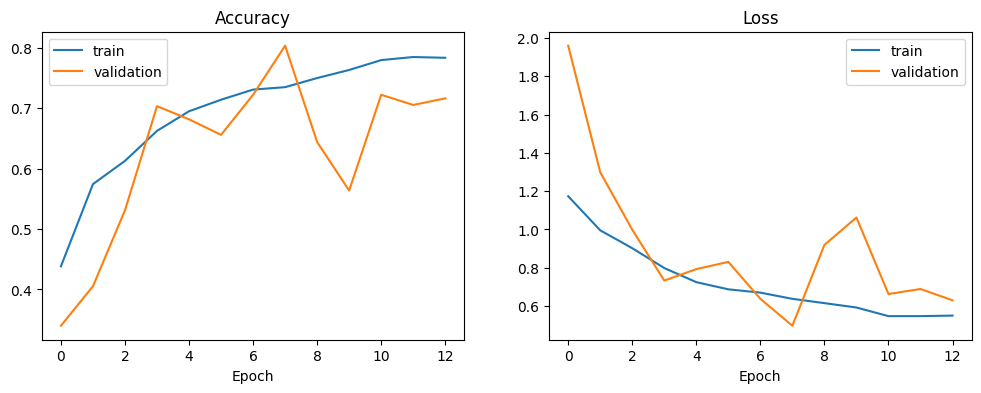

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.savefig("../reports/learning_curves.png", dpi=150)
plt.show()

if mlflow.active_run():
    mlflow.log_artifact("../reports/learning_curves.png", "figures")
    mlflow.end_run()